In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sqlalchemy import create_engine

plt.rcParams["figure.figsize"] = (12, 4)
sns.set(style="whitegrid")

print("Imported successfully")


Imported successfully


In [2]:
meds = pd.read_csv("medications_metadata.csv")
demand = pd.read_csv("pharmacy_demand_1yr.csv")

print("Medication Metadata:")
display(meds.head())

print("Demand Data:")
display(demand.head())

print("Rows in demand:", len(demand))


Medication Metadata:


,med_id,med_name,drug_class,base_daily_demand
0,1,Amoxicillin 500mg,Antibiotic,22
1,2,Azithromycin 250mg,Antibiotic,18
2,3,Lisinopril 10mg,Antihypertensive,16
3,4,Amlodipine 5mg,Antihypertensive,14
4,5,Metformin 500mg,Antidiabetic,20


Demand Data:


,date,med_id,demand,weekday,is_weekend,season,flu_season,allergy_season,shortage_flag,supplier_delay_flag
0,2024-01-01,1,46,0,0,Winter,1,0,0,0
1,2024-01-01,2,21,0,0,Winter,1,0,0,0
2,2024-01-01,3,22,0,0,Winter,1,0,0,0
3,2024-01-01,4,19,0,0,Winter,1,0,0,0
4,2024-01-01,5,16,0,0,Winter,1,0,0,0


Rows in demand: 7300


In [3]:
df = demand.merge(meds, on="med_id", how="left")

df.head(), df.shape


(         date  med_id  demand  weekday  is_weekend  season  flu_season  \
 0  2024-01-01       1      46        0           0  Winter           1   
 1  2024-01-01       2      21        0           0  Winter           1   
 2  2024-01-01       3      22        0           0  Winter           1   
 3  2024-01-01       4      19        0           0  Winter           1   
 4  2024-01-01       5      16        0           0  Winter           1   
 
    allergy_season  shortage_flag  supplier_delay_flag            med_name  \
 0               0              0                    0   Amoxicillin 500mg   
 1               0              0                    0  Azithromycin 250mg   
 2               0              0                    0     Lisinopril 10mg   
 3               0              0                    0      Amlodipine 5mg   
 4               0              0                    0     Metformin 500mg   
 
          drug_class  base_daily_demand  
 0        Antibiotic                

In [4]:
# make copy so to compare raw vs dirty vs clean
dirty_df = df.copy()

# 1) missing values (~2% of data) 
import numpy as np

nan_rows = dirty_df.sample(frac=0.02, random_state=42).index
dirty_df.loc[nan_rows, "demand"] = np.nan

# 2) introduce duplicate rows (~1%)
dupes = dirty_df.sample(frac=0.01, random_state=43)
dirty_df = pd.concat([dirty_df, dupes], ignore_index=True)

# 3) introduce outliers 
outlier_idx = dirty_df.sample(15, random_state=44).index
dirty_df.loc[outlier_idx, "demand"] = dirty_df.loc[outlier_idx, "demand"] * 6

print("Original rows:", len(df))
print("Dirty rows:", len(dirty_df))
dirty_df.head()


Original rows: 7300
Dirty rows: 7373


,date,med_id,demand,weekday,is_weekend,season,flu_season,allergy_season,shortage_flag,supplier_delay_flag,med_name,drug_class,base_daily_demand
0,2024-01-01,1,46.0,0,0,Winter,1,0,0,0,Amoxicillin 500mg,Antibiotic,22
1,2024-01-01,2,21.0,0,0,Winter,1,0,0,0,Azithromycin 250mg,Antibiotic,18
2,2024-01-01,3,22.0,0,0,Winter,1,0,0,0,Lisinopril 10mg,Antihypertensive,16
3,2024-01-01,4,19.0,0,0,Winter,1,0,0,0,Amlodipine 5mg,Antihypertensive,14
4,2024-01-01,5,16.0,0,0,Winter,1,0,0,0,Metformin 500mg,Antidiabetic,20


In [5]:
clean_df = dirty_df.copy()

# 1) drop duplicates
before = len(clean_df)
clean_df = clean_df.drop_duplicates()
after = len(clean_df)

print(f"Duplicates removed: {before - after}")

#2) fix missing values in demand
missing_before = clean_df["demand"].isna().sum()
print("Missing before:", missing_before)

# fill missing demand per-medication using median demand of that medication
clean_df["demand"] = clean_df.groupby("med_id")["demand"].transform(
    lambda s: s.fillna(s.median())
)

missing_after = clean_df["demand"].isna().sum()
print("Missing after:", missing_after)

#3) fix outliers by clipping to 99th percentile 
q99 = clean_df["demand"].quantile(0.99)
clean_df["demand"] = clean_df["demand"].clip(0, q99)

clean_df.head()



Duplicates removed: 73
Missing before: 146
Missing after: 0


,date,med_id,demand,weekday,is_weekend,season,flu_season,allergy_season,shortage_flag,supplier_delay_flag,med_name,drug_class,base_daily_demand
0,2024-01-01,1,35.0,0,0,Winter,1,0,0,0,Amoxicillin 500mg,Antibiotic,22
1,2024-01-01,2,21.0,0,0,Winter,1,0,0,0,Azithromycin 250mg,Antibiotic,18
2,2024-01-01,3,22.0,0,0,Winter,1,0,0,0,Lisinopril 10mg,Antihypertensive,16
3,2024-01-01,4,19.0,0,0,Winter,1,0,0,0,Amlodipine 5mg,Antihypertensive,14
4,2024-01-01,5,16.0,0,0,Winter,1,0,0,0,Metformin 500mg,Antidiabetic,20


In [6]:
clean_df.to_csv("pharmacy_demand_clean.csv", index=False)
print("Saved clean dataset to pharmacy_demand_clean.csv")


Saved clean dataset to pharmacy_demand_clean.csv


In [7]:
from sqlalchemy import create_engine

engine = create_engine("sqlite:///pharmacy_inventory.db")

# save two tables
clean_df.to_sql("demand_data", engine, if_exists="replace", index=False)
meds.to_sql("medications", engine, if_exists="replace", index=False)

print("Tables saved to pharmacy_inventory.db")


Tables saved to pharmacy_inventory.db


In [8]:
season_stats = pd.read_sql("""
SELECT season, AVG(demand) AS avg_demand
FROM demand_data
GROUP BY season
ORDER BY avg_demand DESC;
""", engine)

season_stats


,season,avg_demand
0,Winter,13.739444
1,Spring,13.361413
2,Fall,13.124176
3,Summer,11.345109


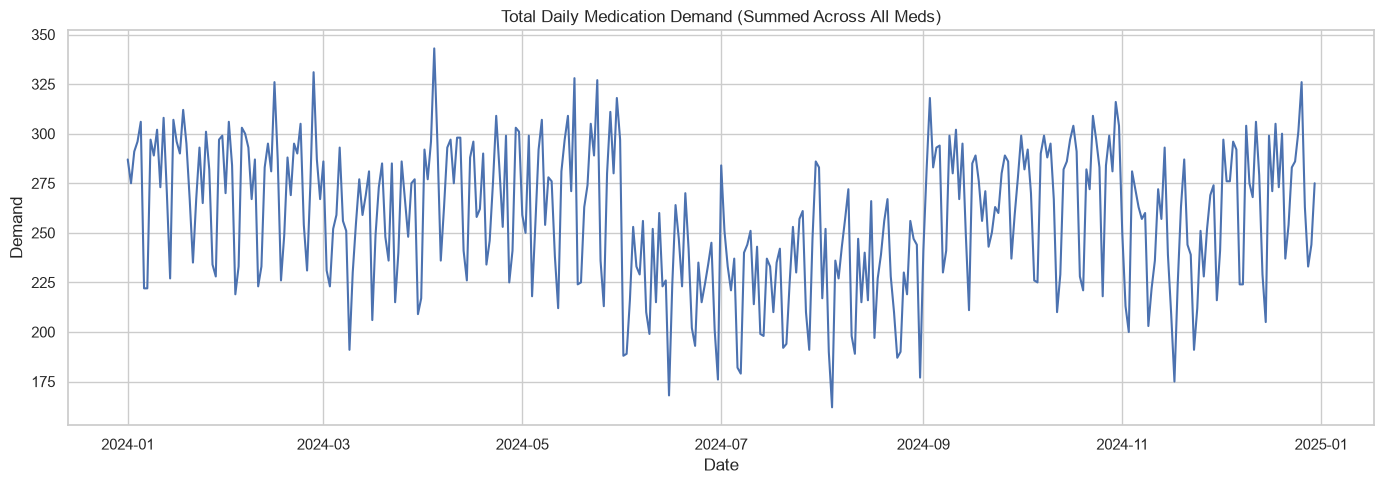

In [21]:
# convert date to datetime
clean_df["date"] = pd.to_datetime(clean_df["date"])

# total daily demand across all medications
daily = clean_df.groupby("date")["demand"].sum()

plt.figure(figsize=(14,5))
plt.plot(daily.index, daily.values)
plt.title("Total Daily Medication Demand (Summed Across All Meds)")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.tight_layout()
plt.show()


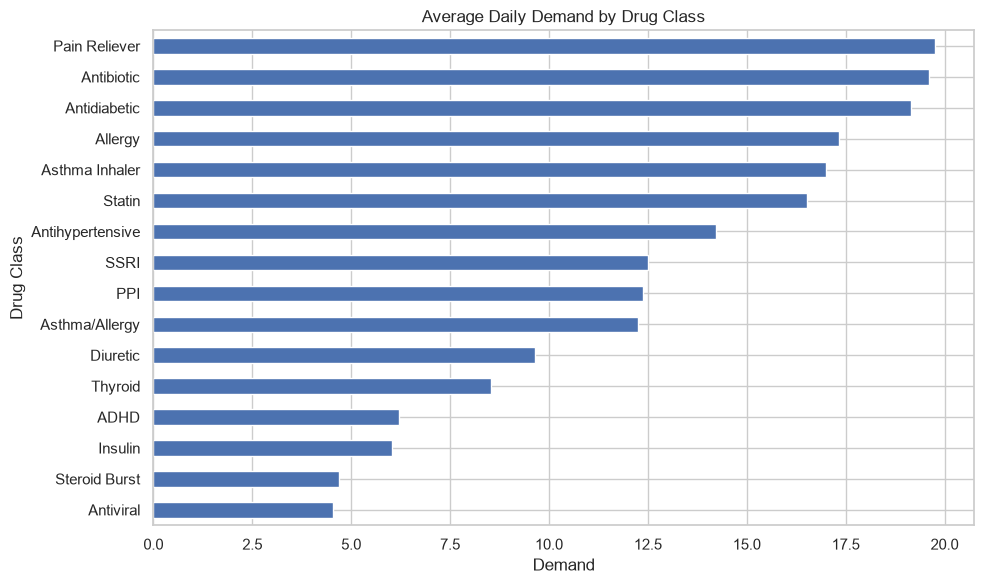

In [9]:
class_demand = clean_df.groupby("drug_class")["demand"].mean().sort_values()

class_demand.plot(kind="barh", figsize=(10,6))
plt.title("Average Daily Demand by Drug Class")
plt.xlabel("Demand")
plt.ylabel("Drug Class")
plt.tight_layout()
plt.show()


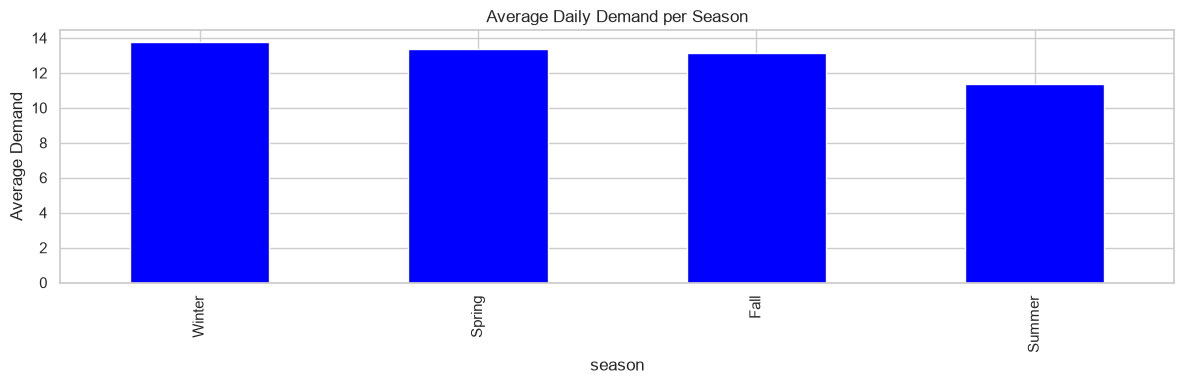

In [23]:
season_avg = clean_df.groupby("season")["demand"].mean().sort_values(ascending=False)

season_avg.plot(kind="bar", color="blue")
plt.title("Average Daily Demand per Season")
plt.ylabel("Average Demand")
plt.tight_layout()
plt.show()


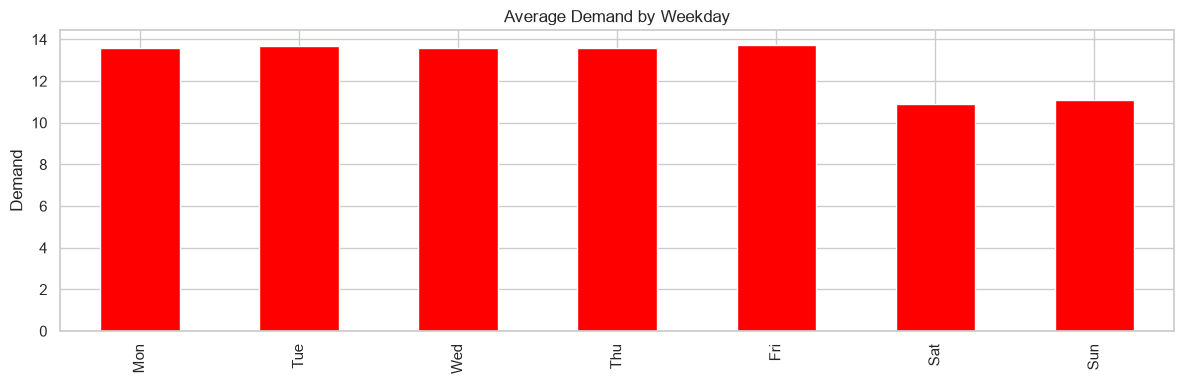

In [10]:
weekday_avg = clean_df.groupby("weekday")["demand"].mean()

weekday_avg.index = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]

weekday_avg.plot(kind="bar", color="red")
plt.title("Average Demand by Weekday")
plt.ylabel("Demand")
plt.tight_layout()
plt.show()


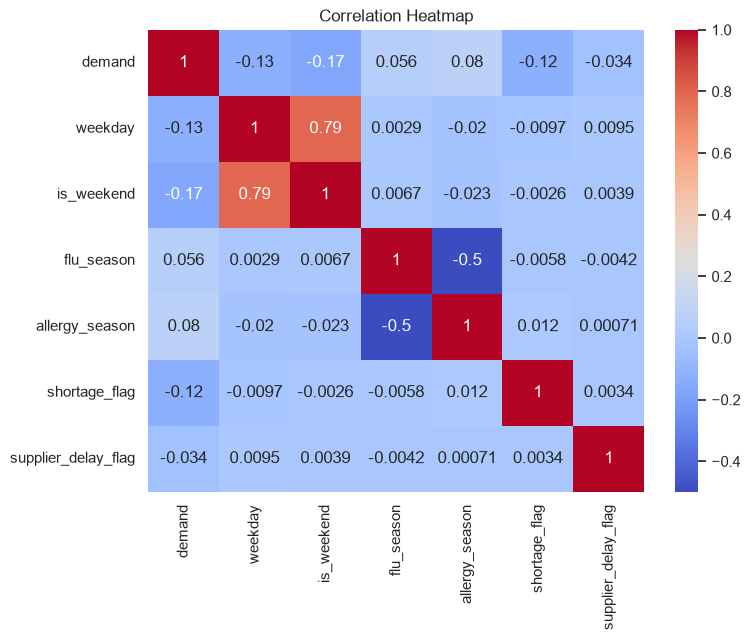

In [25]:
numeric_cols = ["demand","weekday","is_weekend","flu_season",
                "allergy_season","shortage_flag","supplier_delay_flag"]

plt.figure(figsize=(8,6))
sns.heatmap(clean_df[numeric_cols].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()


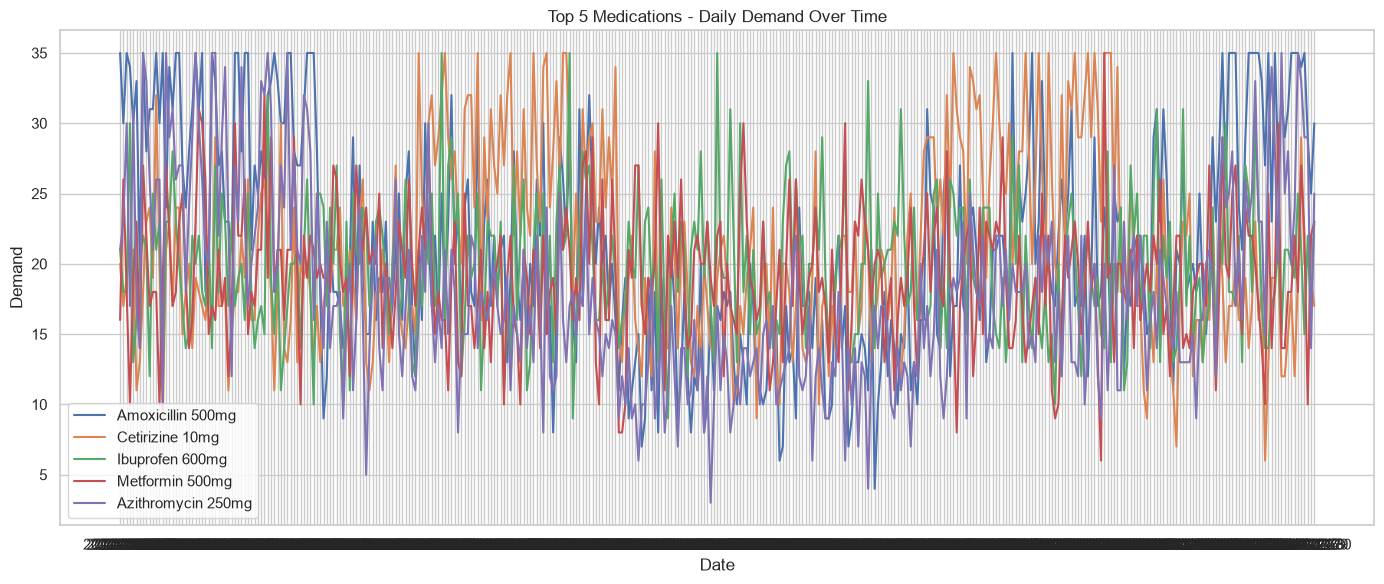

In [11]:
top5 = clean_df.groupby("med_name")["demand"].mean().sort_values(ascending=False).head(5).index

subset = clean_df[clean_df["med_name"].isin(top5)]

plt.figure(figsize=(14,6))
for med in top5:
    med_data = subset[subset["med_name"] == med].groupby("date")["demand"].sum()
    plt.plot(med_data.index, med_data.values, label=med)

plt.legend()
plt.title("Top 5 Medications - Daily Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.tight_layout()
plt.show()


In [12]:
# predict daily demand using these features.

feature_cols = ["weekday", "is_weekend", "flu_season",
                "allergy_season", "shortage_flag", "supplier_delay_flag"]

# One-hot encode medication IDs so the model learns
# different demand patterns for each medication
medication_features = pd.get_dummies(
    clean_df["med_id"].astype(str),
    prefix="med",
    dtype=int
)

X = pd.concat(
    [clean_df[feature_cols].reset_index(drop=True),
     medication_features.reset_index(drop=True)],
    axis=1
)

y = clean_df["demand"]


print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Medication feature columns:", medication_features.columns.tolist())


Feature matrix shape: (7300, 26)
Target shape: (7300,)
Medication feature columns: ['med_1', 'med_10', 'med_11', 'med_12', 'med_13', 'med_14', 'med_15', 'med_16', 'med_17', 'med_18', 'med_19', 'med_2', 'med_20', 'med_3', 'med_4', 'med_5', 'med_6', 'med_7', 'med_8', 'med_9']


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=False
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 5840
Testing rows: 1460


In [14]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

rf = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = mean_squared_error(y_test, rf_pred) ** 0.5

print("Random Forest MAE:", rf_mae)
print("Random Forest RMSE:", rf_rmse)


Random Forest MAE: 3.1434913768992274
Random Forest RMSE: 4.089520169705534


In [15]:
import xgboost
xgboost.__version__


'3.4.1'

In [16]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

xgb = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.9,
    colsample_bytree=0.9,
    random_state=42,
    objective="reg:squarederror"
)

xgb.fit(X_train, y_train)

xgb_pred = xgb.predict(X_test)

xgb_mae = mean_absolute_error(y_test, xgb_pred)
xgb_rmse = mean_squared_error(y_test, xgb_pred) ** 0.5

print("XGBoost MAE:", xgb_mae)
print("XGBoost RMSE:", xgb_rmse)


XGBoost MAE: 3.082151907845719
XGBoost RMSE: 4.024130245821897


<Figure size 1000x600 with 0 Axes>

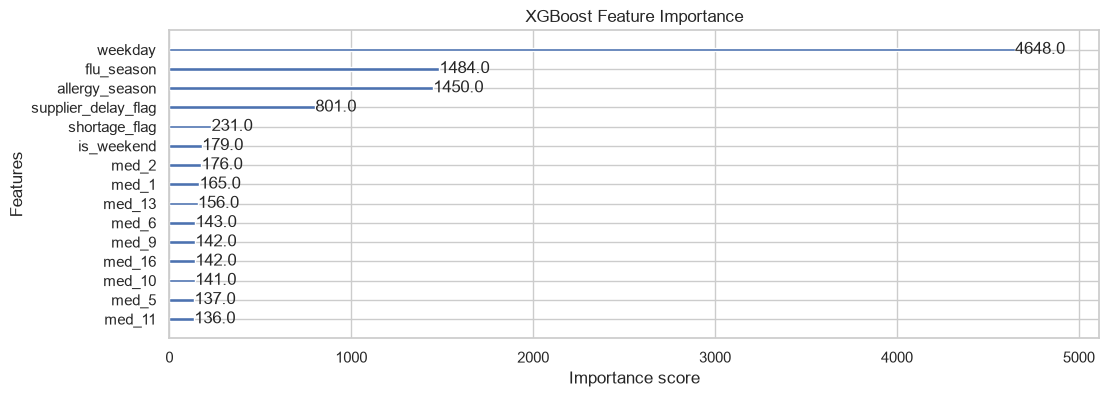

In [17]:
from xgboost import plot_importance
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plot_importance(xgb, max_num_features=15)
plt.title("XGBoost Feature Importance")
plt.show()


In [18]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    "n_estimators": [200, 300, 400, 500],
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5, 7],
}

xgb_model = XGBRegressor(objective="reg:squarederror", random_state=42)

random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_grid,
    n_iter=25,
    scoring="neg_mean_absolute_error",
    cv=3,
    verbose=2,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

print("Best Params:", random_search.best_params_)
best_xgb = random_search.best_estimator_


Fitting 3 folds for each of 25 candidates, totalling 75 fits
[CV] END colsample_bytree=1.0, learning_rate=0.01, max_depth=3, min_child_weight=5, n_estimators=300, subsample=0.7; total time=   0.2s
[CV] END colsample_bytree=1.0, learning_rate=0.01, max_depth=3, min_child_weight=5, n_estimators=300, subsample=0.7; total time=   0.2s
[CV] END colsample_bytree=0.7, learning_rate=0.01, max_depth=6, min_child_weight=3, n_estimators=400, subsample=1.0; total time=   0.3s
[CV] END colsample_bytree=0.7, learning_rate=0.01, max_depth=6, min_child_weight=3, n_estimators=400, subsample=1.0; total time=   0.3s
[CV] END colsample_bytree=0.7, learning_rate=0.01, max_depth=6, min_child_weight=3, n_estimators=400, subsample=1.0; total time=   0.3s
[CV] END colsample_bytree=0.9, learning_rate=0.1, max_depth=8, min_child_weight=1, n_estimators=300, subsample=1.0; total time=   0.3s
[CV] END colsample_bytree=0.9, learning_rate=0.1, max_depth=8, min_child_weight=1, n_estimators=300, subsample=1.0; total ti

In [19]:
best_pred = best_xgb.predict(X_test)

best_mae = mean_absolute_error(y_test, best_pred)
best_rmse = mean_squared_error(y_test, best_pred) ** 0.5

print("Tuned XGBoost MAE:", best_mae)
print("Tuned XGBoost RMSE:", best_rmse)


Tuned XGBoost MAE: 3.0391640552332344
Tuned XGBoost RMSE: 3.973689781450878


In [20]:
results = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost", "Tuned XGBoost"],
    "MAE": [rf_mae, xgb_mae, best_mae],
    "RMSE": [rf_rmse, xgb_rmse, best_rmse]
})

results


,Model,MAE,RMSE
0,Random Forest,3.143491,4.08952
1,XGBoost,3.082152,4.02413
2,Tuned XGBoost,3.039164,3.97369


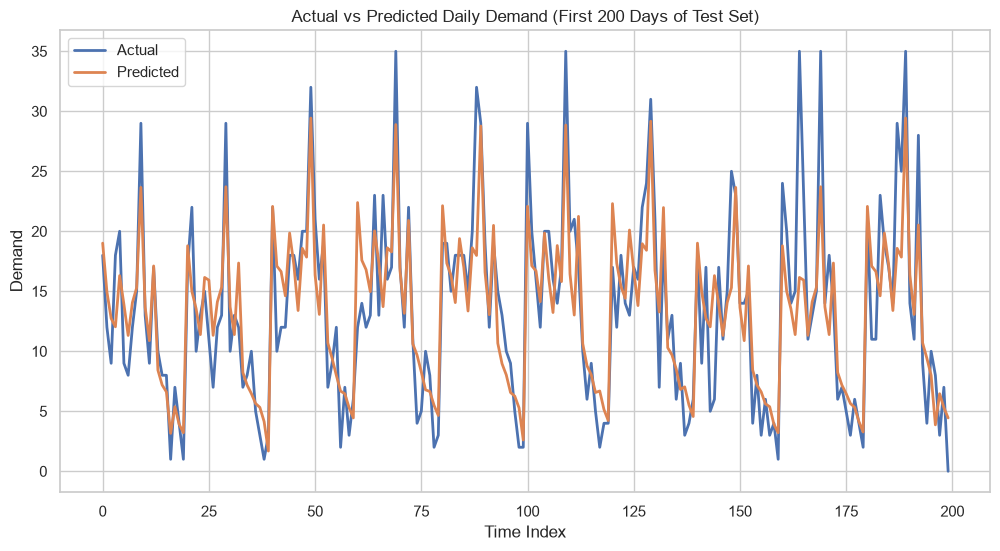

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(y_test.values[:200], label="Actual", linewidth=2)
plt.plot(best_pred[:200], label="Predicted", linewidth=2)
plt.title("Actual vs Predicted Daily Demand (First 200 Days of Test Set)")
plt.xlabel("Time Index")
plt.ylabel("Demand")
plt.legend()
plt.show()


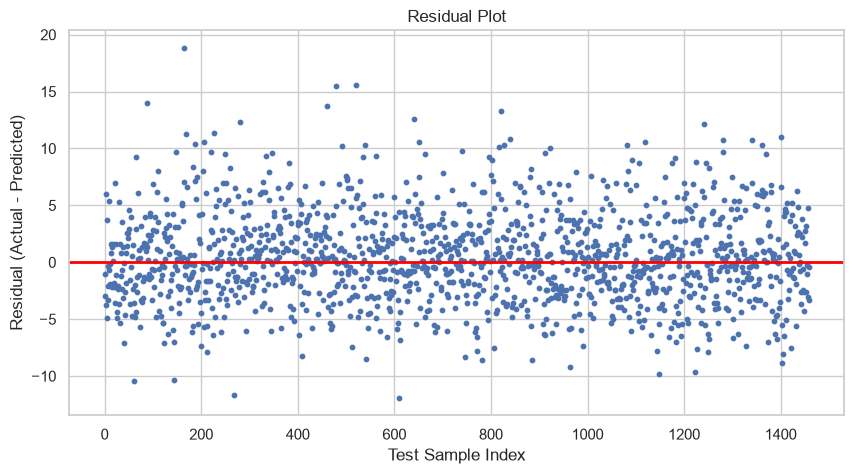

In [22]:
residuals = y_test - best_pred

plt.figure(figsize=(10,5))
plt.scatter(range(len(residuals)), residuals, s=10)
plt.axhline(0, color='red', linewidth=2)
plt.title("Residual Plot")
plt.xlabel("Test Sample Index")
plt.ylabel("Residual (Actual - Predicted)")
plt.show()


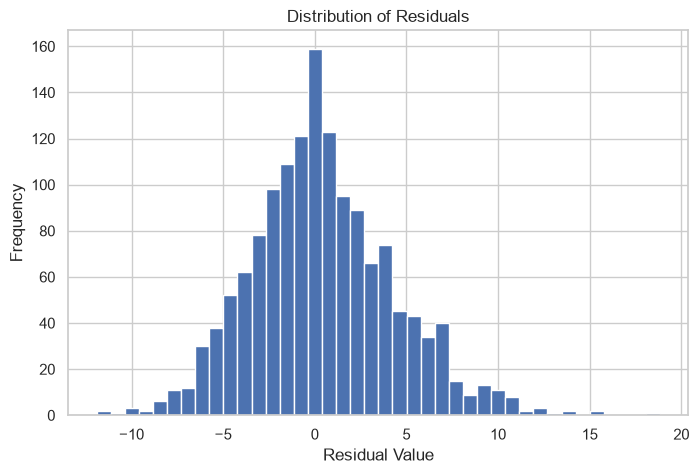

In [23]:
plt.figure(figsize=(8,5))
plt.hist(residuals, bins=40)
plt.title("Distribution of Residuals")
plt.xlabel("Residual Value")
plt.ylabel("Frequency")
plt.show()


In [24]:

import pandas as pd

clean_df = pd.read_csv(
    "pharmacy_demand_clean.csv",
    parse_dates=["date"]
)

print("Rows:", len(clean_df))
print("Columns:", clean_df.columns.tolist())
print("Medications:", clean_df["med_id"].nunique())
print("Latest date:", clean_df["date"].max())

Rows: 7300
Columns: ['date', 'med_id', 'demand', 'weekday', 'is_weekend', 'season', 'flu_season', 'allergy_season', 'shortage_flag', 'supplier_delay_flag', 'med_name', 'drug_class', 'base_daily_demand']
Medications: 20
Latest date: 2024-12-30 00:00:00


In [25]:

feature_cols = [
    "weekday",
    "is_weekend",
    "flu_season",
    "allergy_season",
    "shortage_flag",
    "supplier_delay_flag"
]

In [26]:

# Generate 30-day forecasts for every medication

import pandas as pd

# Create the next 30 days of dates
last_date = pd.to_datetime(clean_df["date"]).max()
future_dates = pd.date_range(
    start=last_date + pd.Timedelta(days=1),
    periods=30,
    freq="D"
)

# Get the medication IDs in the training data
medication_ids = sorted(clean_df["med_id"].unique())

# Build one row for each medication and future date
future_rows = []

for med_id in medication_ids:
    for date in future_dates:
        future_rows.append({
            "date": date,
            "med_id": med_id,
            "weekday": date.weekday(),
            "is_weekend": int(date.weekday() >= 5),
            "flu_season": int(date.month in [10, 11, 12, 1, 2, 3]),
            "allergy_season": int(date.month in [3, 4, 5, 6]),
            "shortage_flag": 0,
            "supplier_delay_flag": 0,
        })

future_df = pd.DataFrame(future_rows)

# Build the same features used during model training
future_calendar = future_df[feature_cols].copy()

future_medication_features = pd.get_dummies(
    future_df["med_id"].astype(str),
    prefix="med",
    dtype=int
)

# Ensure future columns match the model's training columns
future_X = pd.concat(
    [future_calendar.reset_index(drop=True),
     future_medication_features.reset_index(drop=True)],
    axis=1
)

future_X = future_X.reindex(columns=X.columns, fill_value=0)

# Predict demand
future_df["predicted_demand"] = best_xgb.predict(future_X)
future_df["predicted_demand"] = future_df["predicted_demand"].clip(lower=0)

# Check results
print("Forecast rows:", len(future_df))
print("Medications:", future_df["med_id"].nunique())
print("Forecast dates:", future_df["date"].nunique())

future_df.head()


Forecast rows: 600
Medications: 20
Forecast dates: 30


,date,med_id,weekday,is_weekend,flu_season,allergy_season,shortage_flag,supplier_delay_flag,predicted_demand
0,2024-12-31,1,1,0,1,0,0,0,28.270096
1,2025-01-01,1,2,0,1,0,0,0,28.012018
2,2025-01-02,1,3,0,1,0,0,0,28.079002
3,2025-01-03,1,4,0,1,0,0,0,28.232958
4,2025-01-04,1,5,1,1,0,0,0,22.413612


In [29]:

print("Medication metadata columns:")
print(meds.columns.tolist())

display(meds.head())

print("Forecast medication IDs:")
print(sorted(future_df["med_id"].unique()))

Medication metadata columns:
['med_id', 'med_name', 'drug_class', 'base_daily_demand']


,med_id,med_name,drug_class,base_daily_demand
0,1,Amoxicillin 500mg,Antibiotic,22
1,2,Azithromycin 250mg,Antibiotic,18
2,3,Lisinopril 10mg,Antihypertensive,16
3,4,Amlodipine 5mg,Antihypertensive,14
4,5,Metformin 500mg,Antidiabetic,20


Forecast medication IDs:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20)]


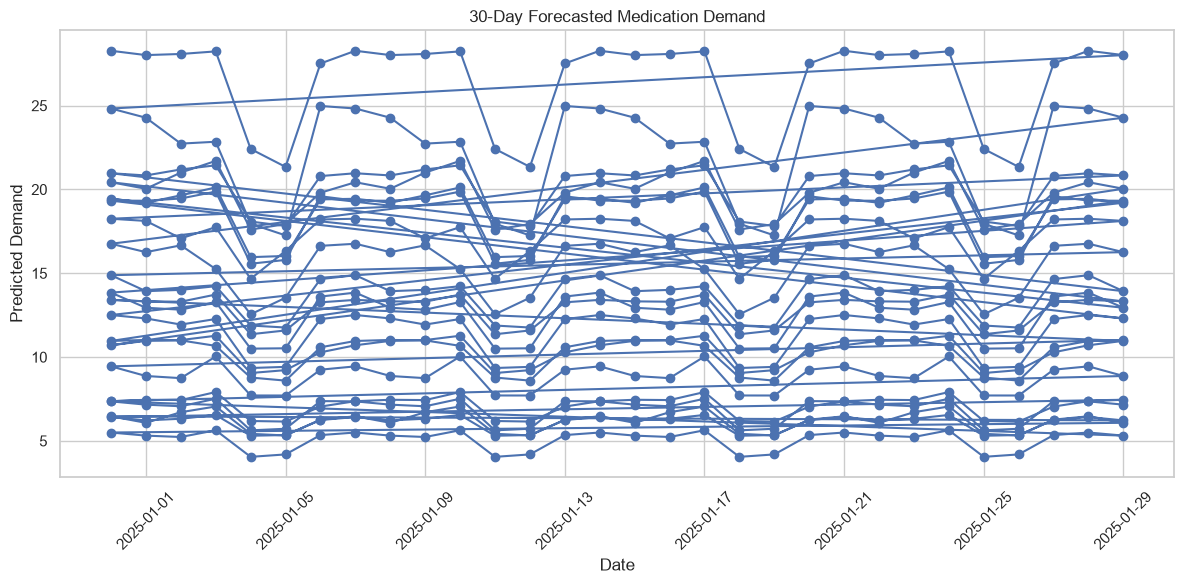

In [30]:
plt.figure(figsize=(12,6))
plt.plot(future_df["date"], future_df["predicted_demand"], marker='o')
plt.title("30-Day Forecasted Medication Demand")
plt.xlabel("Date")
plt.ylabel("Predicted Demand")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


In [31]:
future_df.to_csv("future_30_day_demand_forecast.csv", index=False)
print("Forecast saved to future_30_day_demand_forecast.csv")

Forecast saved to future_30_day_demand_forecast.csv


In [32]:

print("Total forecast rows:", len(future_df))
print("Number of medications:", future_df["med_id"].nunique())
print("Number of forecast dates:", future_df["date"].nunique())

print("\nForecasts by medication:")
display(
    future_df.groupby("med_id")["predicted_demand"]
    .agg(["count", "mean", "min", "max"])
    .round(2)
)

Total forecast rows: 600
Number of medications: 20
Number of forecast dates: 30

Forecasts by medication:


,count,mean,min,max
med_id,,,,
1,30,26.389999,21.340000,28.270000
2,30,22.290001,17.260000,24.980000
3,30,15.450000,12.550000,16.760000
4,30,13.670000,11.760000,14.880000
5,30,20.209999,17.820000,21.440001
6,30,17.270000,14.670000,18.250000
7,30,12.560000,10.500000,13.850000
8,30,18.600000,15.960000,20.120001
9,30,11.500000,9.350000,12.510000
